In [ ]:
# ติดตั้งแพ็กเกจเมื่อรันใน repo — บน Kaggle มี pandas/matplotlib พร้อมอยู่แล้ว
from pathlib import Path

if Path("requirements-offline.txt").exists():
    get_ipython().run_line_magic(
        "pip", "install -r requirements-offline.txt --quiet")
else:
    print("ข้ามการติดตั้ง — ใช้แพ็กเกจที่มีใน environment (เช่น Kaggle)")

# Module M5 — สถิติที่ใช้ได้จริง

|  |  |
|---|---|
| **เวลา** | Day 2, 09:00–10:15 (75 นาที) · Offline (CPU) |
| **ข้อมูล** | Palmer Penguins · ราคาข้าวหอมมะลิ 105 (โบนัสไทย) |

**เมื่อจบโมดูลนี้ ผู้เรียนจะ...**

- อ่าน `describe()` ให้ออก และเลือกสถิติให้ตรงกับคำถาม
- เลือก mean หรือ median อย่างมีเหตุผล — รู้ว่าเมื่อไหร่ "ค่าเฉลี่ย" หลอกเรา
- วัดการกระจายด้วย std และ IQR แล้วแปลผลเป็นภาษาคน
- ดูรูปทรงข้อมูลด้วย histogram ก่อนเชื่อตัวเลขเดียว

**ข้อมูลที่ใช้ (citation):**

> Gorman, K. B., Williams, T. D. & Fraser, W. R. (2014). *Ecological
> sexual dimorphism and environmental variation within a common species
> biomass range: Antarctic penguins*. PLoS ONE 9(3):e90081 — ข้อมูล Palmer
> Penguins (CC0-1.0; package: Horst, Hill & Gorman 2020, doi:10.5281/zenodo.3960218)
>
> สำนักงานเศรษฐกิจการเกษตร (2565–2568). *ราคาข้าวเปลือกเจ้าหอมมะลิ 105
> รายเดือน* data.go.th (Open Data Common)

## 1. สถิติคือ "สรุปหลายพันตัวเลขให้เหลือไม่กี่ตัว"

ตารางเพนกวิน 344 แถว ตาเราอ่านไม่ไหว — สถิติเชิงพรรณนาคือการย่อ
ทั้งตารางให้เหลือตัวเลขไม่กี่ตัวที่บอกได้ว่า "ข้อมูลชุดนี้หน้าตาเป็นอย่างไร"

สองคำถามที่สถิติต้องตอบได้เสมอ:

1. **ค่าทั่วไปอยู่ตรงไหน** (ค่ากลาง — mean / median)
2. **ค่ากระจายกว้างแค่ไหน** (การกระจาย — std / IQR)

pandas คำนวณให้หมด — งานของเราไม่ใช่คำนวณ แต่คือ**เลือกให้ถูกคำถาม และแปลผลให้คนอ่านเข้าใจ**

In [ ]:
import pandas as pd
from pathlib import Path

import os


def data_root() -> Path:
    """หาโฟลเดอร์ datasets/ — ใช้ได้ทั้ง repo local, venv และ Kaggle.

    ลำดับการค้นหา:
    1. environment variable COURSE_DATA_ROOT (ชี้ตรงไปที่โฟลเดอร์ datasets)
    2. โฟลเดอร์ datasets/ ที่อยู่ระดับเดียวกับโน้ตบุ๊กหรือแม่ขึ้นไป
       (repo local)
    3. /kaggle/input — ทั้งกรณีอัปโหลด datasets/ ทั้งโฟลเดอร์
       หรืออัปโหลดแต่ละชุดแยกกัน (ชื่อโฟลเดอร์ต้องตรงกับใน datasets/)
    """
    env = os.environ.get("COURSE_DATA_ROOT")
    if env:
        return Path(env)
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "datasets").is_dir():
            return p / "datasets"
    kaggle = Path("/kaggle/input")
    if kaggle.is_dir():
        hits = sorted(kaggle.glob("**/datasets"))
        if hits:
            return hits[0]
        return kaggle
    raise SystemExit(
        "ไม่พบโฟลเดอร์ datasets/ — ตั้ง COURSE_DATA_ROOT "
        "หรือวาง datasets/ ไว้ข้างโน้ตบุ๊ก")

DATA = data_root() / "palmer_penguins"  # noqa: E305

penguins = pd.read_csv(DATA / "penguins.csv")
# ค่าหาย 19 ช่องจาก 344 แถว (สอนใน M3) — แล็บนี้ตัดทิ้งเพื่อความเรียบง่าย
# (bare .dropna() = ตัดแถวที่มีช่องว่าง "ที่ไหนก็ได้" ทิ้งทั้งแถว)
penguins = penguins.dropna()
print(f"เหลือ {len(penguins)} แถวจาก 344")

## 2. ค่ากลาง — เริ่มจากคำสั่งเดียว: `.describe()`

คำสั่งเดียวที่ควรพิมพ์ทุกครั้งก่อนแตะตารางตัวเลข:

In [ ]:
penguins["body_mass_g"].describe()

## ✏️ ลองเอง 1 — ค่าสถิติ 5 ตัวเลขของความยาวปีก

ใช้ `.describe()` สรุปค่าสถิติของคอลัมน์ `penguins["flipper_length_mm"]` แล้วพิมพ์ผลลัพธ์ออกมา

**คำใบ้:** ใช้เมธอด `.describe()` บนคอลัมน์ที่สนใจ แล้วใช้ `print()` แสดงผล

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# สรุปค่าสถิติของ flipper_length_mm ด้วย .describe()


<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">count    333.000000
mean     200.966967
std       14.015765
min      172.000000
25%      190.000000
50%      197.000000
75%      213.000000
max      231.000000
Name: flipper_length_mm, dtype: float64</pre>

</div>

อ่านแต่ละบรรทัดให้ออก:

| แถว | คืออะไร |
|---|---|
| `count` | จำนวนค่าที่ไม่ว่าง — ดูก่อนว่าตัวเลขคิดจากกี่แถว |
| `mean` | ค่าเฉลี่ย (ผลรวม ÷ จำนวน) |
| `std` | ความกระจายมาตรฐาน — ดู §3 |
| `min` / `max` | ค่าต่ำสุด / สูงสุด — จุดตรวจ "ค่าแปลกหรือเปล่า" |
| `25%` / `50%` / `75%` | ควอร์ไทล์ — 50% คือ median ตัวจริง |

**โน้ตเก่าที่ต้องแก้:** คนมักจำกันว่า "เฉลี่ย = ตัวแทนข้อมูล" — จริงบางทีเท่านั้น

In [ ]:
# ทำไม? ลองกับตัวเลขเงินเดือนทีมงาน 7 คน (หน่วย: บาท)
salaries = [25_000, 28_000, 30_000, 32_000, 35_000, 40_000, 250_000]
sal = pd.Series(salaries)   # แปลง list เป็น Series ใช้เครื่องมือ pandas ได้
print(f"mean   = {sal.mean():,.0f}")
print(f"median = {sal.median():,.0f}")

mean **62,857** บาท — แต่ทีมนี้ไม่มีใครได้เท่านั้น! เงินเดือนผู้บริหารคนเดียว
ลากค่าเฉลี่ยลอยขึ้นไป ส่วน median (ตัวกลางตัวจริง = 32,000) ยังบอกเรื่อง
"คนทั่วไปในทีม" ได้

**กฎนิ้วโป้ง:** ข้อมูลเรื่อง**เงิน ราคา เวลารอ** มักเบ้ (มีค่าสูงผิดปกติไม่กี่ตัว) —
รายงานด้วย **median** ไว้ก่อน แล้วเสริม mean ถ้าจำเป็น

## ✏️ ลองเอง 2 — mean หรือ median เล่าเรื่องทีมได้ดีกว่า

คำนวณ mean และ median ของ `salaries` (เงินเดือนทีม 7 คน) แล้วพิมพ์ทั้งสองค่าในบรรทัดเดียวด้วยรูปแบบ `mean = <ค่า> | median = <ค่า>` จากนั้นเขียนโน้ตสั้น ๆ ว่าค่าไหนอธิบาย "คนส่วนใหญ่ในทีม" ได้ดีกว่ากัน เพราะอะไร

**คำใบ้:** สร้าง `pd.Series` จากลิสต์เงินเดือน แล้วใช้ `.mean()` และ `.median()` — จัดรูปแบบบรรทัดเดียวด้วย f-string

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# พิมพ์ mean และ median ของ salaries ในบรรทัดเดียว
# (ตัวเลขมี comma คั่นหลักพัน)
# แล้วเขียนโน้ต 1 บรรทัดว่าค่าไหนอธิบายทีมนี้ได้ดีกว่า


<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">mean = 62,857 | median = 32,000

median (32,000) อธิบายทีมได้ดีกว่า — mean ถูกลากขึ้นด้วยเงินเดือนผู้บริหาร
คนเดียวที่ 250,000</pre>

</div>

## 3. การกระจาย — ค่ากลางเท่ากันอาจมาจากคนละโลก

สองทีมซ่อมเครื่อง ใช้เวลาเฉลี่ยเท่ากัน 30 นาที/เครื่อง:

- ทีม A: ทุกงานอยู่ช่วง 28–32 นาที — นิ่ง โปรแกรมงานได้
- ทีม B: บางงาน 10 นาที บางงาน 90 นาที — เฉลี่ยเท่ากัน แต่ลูกค้าโทรด่าต่างกัน

สถิติที่จับเรื่องนี้ได้สองตัว:

In [ ]:
mass = penguins["body_mass_g"]

print(f"std  = {mass.std():,.0f} g   (ระยะเฉลี่ยที่ค่าหลุดจาก mean)")

q1, q3 = mass.quantile([0.25, 0.75])
print(f"IQR  = {q3 - q1:,.0f} g   (กลาง 50% ของข้อมูลอยู่ช่วง "
      f"{q1:,.0f}–{q3:,.0f} g)")

- **std** — ตัวเลขยิ่งใหญ่ = ข้อมูลยิ่งกระจัดกระจาย หน่วยเดียวกับข้อมูล (กรัม)
- **IQR** (ช่วง Q3 − Q1) — ความกว้างของ "กลาง 50%" ไม่สนใจค่าสุดขอบสองข้าง
  จึงไม่โดน outlier ลาก

**ตอนรายงาน:** ตัวเลขเดี่ยวไม่มีวันพอ — "เฉลี่ย 4,200 กรัม" ต้องแถม
"± std 800" หรือ "กลาง 50% อยู่ 3,550–4,775" ถึงจะเชื่อได้

## ✏️ ลองเอง 3 — คำนวณส่วนเบี่ยงเบนมาตรฐาน (std)

คำนวณค่าส่วนเบี่ยงเบนมาตรฐาน (`std`) ของความยาวปีก `penguins["flipper_length_mm"]` แล้วพิมพ์ผลลัพธ์ในรูปแบบ `std = <ค่า>` ปัดเศษทศนิยม 2 ตำแหน่ง

**คำใบ้:** ใช้เมธอด `.std()` กับคอลัมน์ความยาวปีก แล้วจัดรูปแบบทศนิยม 2 ตำแหน่งด้วย f-string

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# คำนวณและพิมพ์ค่า std ของ flipper_length_mm ทศนิยม 2 ตำแหน่ง


<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">std = 14.02</pre>

</div>

## ✏️ ลองเอง 4 — คำนวณพิสัยระหว่างควอร์ไทล์ (IQR)

คำนวณค่า IQR (Interquartile Range = Q3 - Q1) ของน้ำหนักเพนกวิน `mass = penguins["body_mass_g"]` โดยใช้ฟังก์ชัน `.quantile()` แล้วพิมพ์ค่า IQR ออกมาแบบจำนวนเต็ม

**คำใบ้:** ใช้เมธอด `.quantile()` หา Q1 กับ Q3 แล้วคำนวณผลต่างเป็น IQR — จัดรูปแบบด้วย f-string

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# คำนวณ q25, q75 และพิมพ์ค่า IQR ของ body_mass_g แบบจำนวนเต็ม


<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">IQR = 1225</pre>

</div>

## 4. สรุปต่อกลุ่ม — สถิติมีประโยชน์จริงเมื่อเอามา**เทียบกัน**

`.groupby()` + `.agg()` เรียนแล้วใน M2 — คราวนี้ขอเพิ่ม `median`/`std`
เข้าชุดการรวม แล้วอ่านตารางให้เป็นเรื่อง:

In [ ]:
by_species = penguins.groupby("species").agg(
    n=("body_mass_g", "size"),
    mean_g=("body_mass_g", "mean"),
    median_g=("body_mass_g", "median"),
    std_g=("body_mass_g", "std"),
)
by_species.round(0)

อ่านออกมาเป็นภาษาคน:

- **Gentoo** หนักกว่าสองชนิดที่เหลือชัดเจน (~5,000 ก. vs ~3,700 ก.)
- **Adelie vs Chinstrap** — mean ใกล้กันมาก แต่ก่อนตัดสินใจให้ดู std และ n
- คอลัมน์ `n` สำคัญเสมอ — กลุ่มที่มีข้อมูล 10 แถวเทียบกับ 300 แถวไม่ได้เลย

## ✏️ ลองเอง 5 — เทียบน้ำหนักเพนกวินรายชนิด

จัดกลุ่ม `penguins` ตาม `species` แล้วคำนวณ **mean และ std** ของ `body_mass_g` ใน `agg(...)` ครั้งเดียว ตั้งชื่อคอลัมน์ `mean_g` และ `std_g` แล้วพิมพ์ตารางสั้น ๆ ออกมา

**คำใบ้:** ใช้ `.groupby()` ร่วมกับ `.agg()` ตั้งชื่อคอลัมน์ใหม่ `mean_g` และ `std_g` — ปิดท้ายด้วย `.round()` ให้อ่านง่าย

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# พิมพ์ตาราง mean และ std ของ body_mass_g แยกตาม species
# ต้องได้ 3 แถว (Adelie, Chinstrap, Gentoo) พร้อมสองคอลัมน์สถิติ


<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">           mean_g  std_g
species                 
Adelie     3706.0  459.0
Chinstrap  3733.0  384.0
Gentoo     5092.0  501.0</pre>

</div>

## ✏️ ลองเอง 6 — ค่ามัธยฐานน้ำหนักแยกตามเกาะ (island)

คำนวณค่ามัธยฐาน (`median`) ของน้ำหนัก `body_mass_g` แยกตามเกาะที่อยู่อาศัย `island` ด้วยคำสั่ง `groupby`

**คำใบ้:** ใช้ `.groupby()` กับคอลัมน์เกาะ แล้วเรียก `.median()` บนน้ำหนักตัว

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# คำนวณค่า median ของ body_mass_g แยกตาม island


<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">island
Biscoe       4800.0
Dream        3700.0
Torgersen    3700.0
Name: body_mass_g, dtype: float64</pre>

</div>

## 5. มองรูปทรงด้วย histogram — ก่อนเชื่อ "ค่าเฉลี่ยรวม"

ตัวเลขใน §2–§4 สรุปทั้ง 333 ตัวรวมกัน — มาดูว่าของจริงกระจายหน้าตาอย่างไร:

In [ ]:
import matplotlib.pyplot as plt  # noqa: E402

plt.rcParams["font.family"] = [
    "DejaVu Sans", "Noto Sans Thai", "Leelawadee UI", "Tahoma",
]

fig, ax = plt.subplots(figsize=(7, 3))
penguins["body_mass_g"].plot.hist(bins=30, ax=ax, color="#457b9d")
ax.set_title("น้ำหนักเพนกวินทั้ง 333 ตัว")
ax.set_xlabel("น้ำหนัก (กรัม)")
plt.show()

กราฟไม่เป็นภูเขาลูกเดียว — มี**สองยอด** (bimodal)

ค่าเฉลี่ยรวม ~4,200 ก. ตกอยู่**ร่องกลาง**ระหว่างสองยอด — แปลว่า
"เพนกวินเฉลี่ยหนัก 4,200 ก." ไม่ตรงกับเพนกวินตัวไหนเลย!

เดาก่อนว่าอะไรแบ่งสองยอด — แล้วลองตรวจ:

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3))
for sex_name, color in [("female", "#e07a5f"), ("male", "#457b9d")]:
    mask = penguins["sex"] == sex_name
    penguins.loc[mask, "body_mass_g"].plot.hist(
        bins=25, alpha=0.55, ax=ax, color=color, label=sex_name)
ax.legend()
ax.set_title("น้ำหนักแยกตามเพศ — ต้นตอของสองยอด")
ax.set_xlabel("น้ำหนัก (กรัม)")
plt.show()

สองยอดมาจาก**เพศ** — ตัวผู้หนักกว่าตัวเมียชัดเจนในทุกชนิด

`.loc[mask, "body_mass_g"]` คือการเลือก "แถวตามเงื่อนไข + คอลัมน์ที่ต้องการ"
พร้อมกันในคำสั่งเดียว (ประโยคเดียวแทนสองขั้น `df[mask]["col"]`)

**บทเรียนหัวใจของโมดูลนี้:** เห็น mean เดียวอย่างเพิ่งเชื่อ — วาด histogram
ดูรูปทรงก่อนเสมอ ถ้ารูปทรงคล้ายกระดิ่งลูกเดียว mean+std พอ
ถ้าหลายยอด = มีกลุ่มซ่อนอยู่ ต้องแยกด้วย `groupby` ก่อนพูดอะไรต่อ

## ✏️ ลองเอง 7 — สร้าง Histogram ของความยาวปีก

วาดกราฟฮิสโตแกรมของ `penguins["flipper_length_mm"]` กำหนดจำนวนช่วง `bins=15` พร้อมขอบแท่งสีขาว `edgecolor="white"` และใส่ป้ายแกน x เป็น "ความยาวปีก (มม.)"

**คำใบ้:** ใช้ `ax.hist()` กับคอลัมน์ความยาวปีก กำหนด `bins`, `color`, `edgecolor` และป้ายแกน x ด้วย `ax.set_xlabel()`

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# วาดฮิสโตแกรม flipper_length_mm (15 bins) พร้อมขอบสีขาวและป้ายแกน x


<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

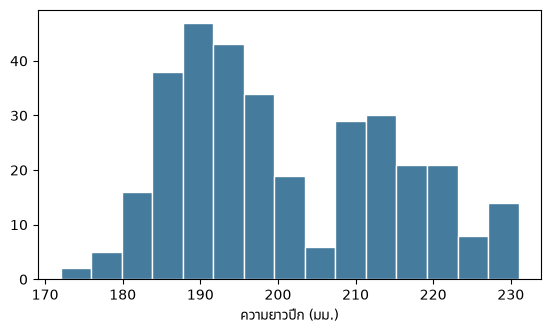

</div>

## 6. โบนัสไทย — ราคาข้าวหอมมะลิ: ข้อมูลเงินใช้ median

ราคาข้าวเปลือกหอมมะลิ 105 รายเดือน (สำนักงานเศรษฐกิจการเกษตร, บาท/ตัน)
โจทย์คลาสสิกของข้อมูลไทย: **ปีเป็น พ.ศ.** (2565 = ค.ศ. 2022)

In [ ]:
rice = pd.read_csv(
    data_root() / "rice_price_105" / "rice105_monthly.csv")
print(f"{len(rice)} เดือน · ปี พ.ศ. {rice['year'].min()}"
      f"–{rice['year'].max()}")
rice["Value"].describe().round(0)

In [ ]:
# เทียบต่อปี: mean กับ median ต่างกันแค่ไหน
rice.groupby("year").agg(
    median_price=("Value", "median"),
    mean_price=("Value", "mean"),
    max_price=("Value", "max"),
).round(0)

## ✏️ ลองเอง 8 — เปรียบเทียบ mean และ median ของราคาข้าวหอมมะลิ

จากตาราง `rice` คำนวณค่า mean และ median ของราคาข้าว (`rice["Value"]`) ตลอดทั้งชุดข้อมูล แล้วพิมพ์ผลต่าง (`mean - median`) ในหน่วยบาทต่อตัน ปัดเศษทศนิยม 1 ตำแหน่ง

**คำใบ้:** ใช้ `.mean()` และ `.median()` บนคอลัมน์ราคา หาผลต่าง แล้วพิมพ์ด้วย f-string ทศนิยม 1 ตำแหน่ง

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# คำนวณผลต่างระหว่าง mean กับ median ของราคาข้าว แล้วพิมพ์ออกมา


<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">ส่วนต่าง mean - median: -14.7 บาท</pre>

</div>

อ่านตาราง: median ต่อปีไต่ขึ้นเรื่อย ๆ (13,184 → 15,288 บาท/ตัน) — และ
mean กับ median ใกล้กันมาก ข้อมูลชุดนี้เบ้ไม่มาก

จุดสอนสำคัญ: กฎ "ข้อมูลเงินใช้ median" เป็นกฎนิ้วโป้ง **ไม่ใช่กฎเหล็ก** —
เลือกตัวเลขไหน ต้องดูข้อมูลจริงก่อนเสมอ (หมายเหตุ: ปี 2568 มีเพียง 8 เดือน
ม.ค.–ส.ค. — อย่าเทียบกับปีเต็มโดยตรง)

## 7. เช็คลิสต์ "สถิติที่ใช้ได้จริง" + สรุป

ก่อนส่งตัวเลขให้ใครอ่าน ตรวจ 5 ข้อ:

1. **พิมพ์ `.describe()` ก่อนพูดอะไร** — count/mean/std/min/quartiles/max
2. ข้อมูลเงิน/ราคา/เวลารอ → **median** เป็นตัวเลขหลัก
3. ตัวเลขเดี่ยวไม่มีวันพอ — แนบ **std หรือ IQR** และ **หน่วย** ไปด้วย
4. เฉลี่ยรวมดูน่าสงสัย → **histogram ดูรูปทรง** ก่อน (bimodal = กลุ่มซ่อนอยู่)
5. เทียบกลุ่ม → `groupby().agg()` และ **ห้ามลืมคอลัมน์ n**

**ต่อไป (M6):** ตัวเลขพวกนี้ไม่ได้เล่าแค่อดีต — แนวโน้มที่เห็นในตาราง
ยืดต่อเข้าอนาคตได้ แต่ต้องรู้จักกับดักของมัน ซึ่งคือชั่วโมงถัดไป